In [14]:
from __future__ import annotations
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from kde_tools.bandwidths import (
    bandwidth_grid_linear_in_psi_beta,
    gaussian_mise_oracle_bandwidth,
)
from kde_tools.density import (
    exact_gaussian_kde_l2_gram,
    exact_oracle_ise_values,
    gaussian_kde_values,
)
from kde_tools.experiments import beta2_bandwidth_selection_counts
from kde_tools.fourier import (
    beta2_divergence_matrix_fft,
    beta2_similarity_matrix_fft,
    kde_family_fft,
)
from kde_tools.gaussian_mixtures import exact_mixture_mise_values
import kde_tools.plotting_functions as kde_plotting_functions
importlib.reload(kde_plotting_functions)
from kde_tools.plotting_functions import (
    plot_bandwidth_distributions,
    plot_perron_vector,
)
from kde_tools.quadrature import (
    compute_quadrature_similarity_matrices,
    quadrature_beta2_divergence_matrix,
    quadrature_grid_for_kdes,
    quadrature_similarity_matrices,
    select_quadrature_similarity_bandwidths,
)
from kde_tools.similarities import (
    beta2_divergence_matrix,
    beta2_similarity_matrix,
    perron_vector,
    select_spectral_bandwidth,
    spectral_choice_from_similarity,
    squared_l2_distance_from_gram,
)

In [15]:
def print_matrix(M):
    print(pd.DataFrame(D2).to_string(index=False, header=False, float_format=lambda x: f"{x:.4f}"))

In [16]:
rng = np.random.default_rng(12345)
n = 200
N = 200
tau = 1.0
samples = rng.normal(loc=0.0, scale=1.0, size=n)
h_grid = bandwidth_grid_linear_in_psi_beta(
    h_min=0.1,
    h_max=1.0,
    beta=2.0,
    grid_size=N,
)
# print(h_grid)
D2 = beta2_divergence_matrix(samples=samples, h_grid=h_grid)
SimMatr = beta2_similarity_matrix(samples=samples, h_grid=h_grid, tau=tau)
# print()
# print_matrix(D2)
# print()
# print_matrix(SimMatr)

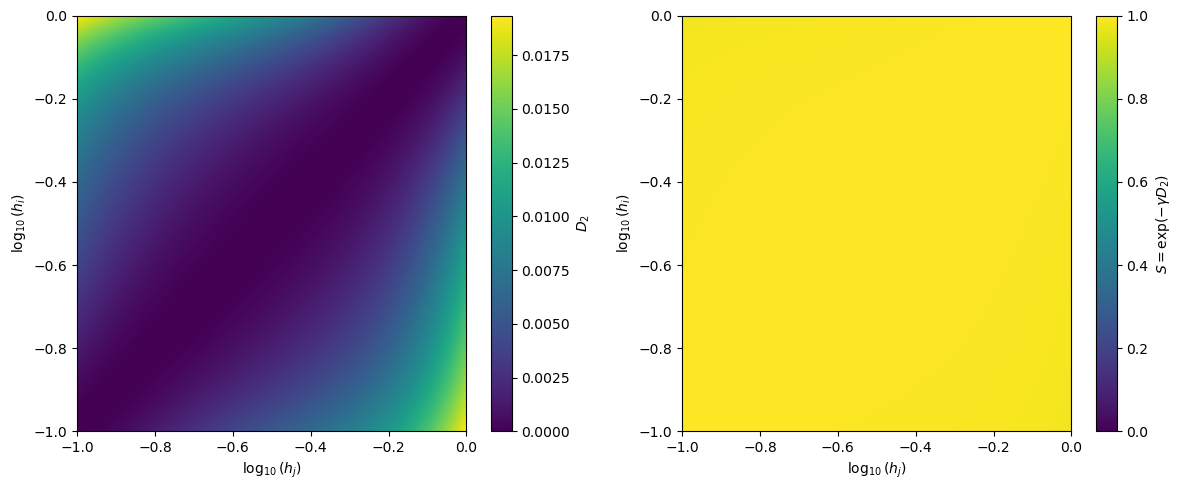

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

extent = [
    np.log10(h_grid[0]),
    np.log10(h_grid[-1]),
    np.log10(h_grid[0]),
    np.log10(h_grid[-1]),
]

image_d2 = axes[0].imshow(
    D2,
    origin="lower",
    aspect="auto",
    extent=extent,
    cmap="viridis",
)
axes[0].set_xlabel(r"$\log_{10}(h_j)$")
axes[0].set_ylabel(r"$\log_{10}(h_i)$")
colorbar_d2 = fig.colorbar(image_d2, ax=axes[0])
colorbar_d2.set_label(r"$D_2$")

image_similarity = axes[1].imshow(
    SimMatr,
    origin="lower",
    aspect="auto",
    extent=extent,
    cmap="viridis",
    vmin=0.0,
    vmax=1.0,
)
axes[1].set_xlabel(r"$\log_{10}(h_j)$")
axes[1].set_ylabel(r"$\log_{10}(h_i)$")
colorbar_similarity = fig.colorbar(image_similarity, ax=axes[1])
colorbar_similarity.set_label(r"$S=\exp(-\gamma D_2)$")

plt.tight_layout()
plt.show()

In [18]:
vec = perron_vector(matrix=SimMatr)
print(vec)

[0.00498656 0.00498708 0.00498759 0.0049881  0.00498859 0.00498908
 0.00498956 0.00499003 0.00499049 0.00499095 0.00499139 0.00499183
 0.00499226 0.00499268 0.00499309 0.0049935  0.00499389 0.00499428
 0.00499466 0.00499503 0.0049954  0.00499575 0.0049961  0.00499644
 0.00499677 0.00499709 0.0049974  0.00499771 0.00499801 0.0049983
 0.00499859 0.00499887 0.00499914 0.0049994  0.00499966 0.00499991
 0.00500015 0.00500039 0.00500062 0.00500084 0.00500106 0.00500127
 0.00500148 0.00500168 0.00500187 0.00500206 0.00500225 0.00500243
 0.0050026  0.00500277 0.00500294 0.0050031  0.00500326 0.00500341
 0.00500356 0.0050037  0.00500384 0.00500398 0.00500411 0.00500424
 0.00500437 0.00500449 0.00500461 0.00500473 0.00500484 0.00500495
 0.00500506 0.00500516 0.00500526 0.00500536 0.00500545 0.00500555
 0.00500564 0.00500572 0.00500581 0.00500589 0.00500597 0.00500604
 0.00500612 0.00500619 0.00500626 0.00500632 0.00500638 0.00500645
 0.0050065  0.00500656 0.00500661 0.00500667 0.00500671 0.00500

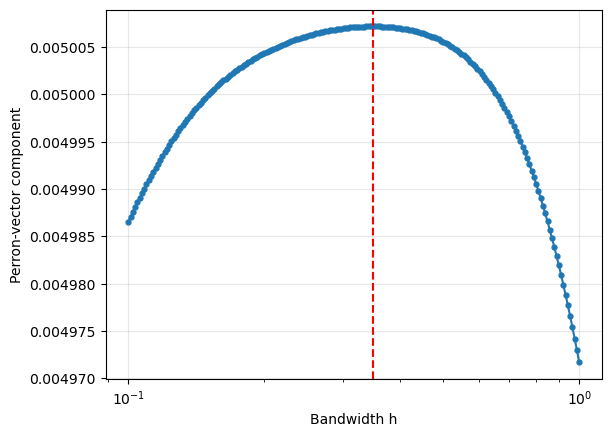

In [19]:
plot_perron_vector(h_grid=h_grid, vector=vec);

Plot the ISE($h$)-curve

In [20]:
ise_values = exact_oracle_ise_values(samples, h_grid, sigma2=1.0)

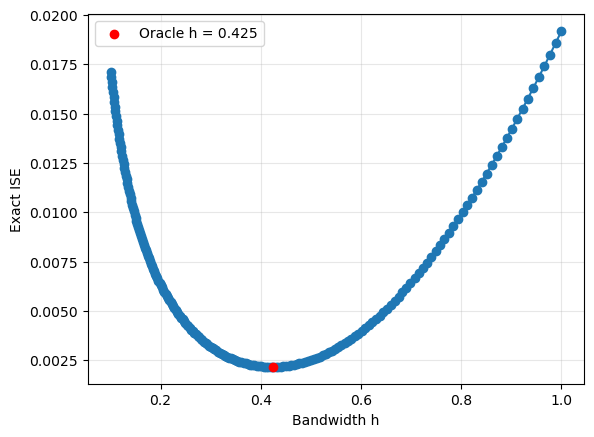

In [21]:
oracle_index = np.argmin(ise_values)

plt.plot(h_grid, ise_values, marker="o")
plt.scatter(
    h_grid[oracle_index],
    ise_values[oracle_index],
    color="red",
    label=f"Oracle h = {h_grid[oracle_index]:.3f}",
    zorder=3,
)
plt.xlabel("Bandwidth h")
plt.ylabel("Exact ISE")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [9]:
choice = spectral_choice_from_similarity(SimMatr)

spectral_index = choice["selected_index"]
spectral_h = h_grid[spectral_index]

ise_values = exact_oracle_ise_values(
    samples=samples,
    h_grid=h_grid,
    sigma2=1.0,
)

oracle_index = int(np.argmin(ise_values))
oracle_h = h_grid[oracle_index]

print(f"Spectral bandwidth: h = {spectral_h:.6f}")
print(f"Oracle bandwidth:   h = {oracle_h:.6f}")
print(f"Spectral ISE:       {ise_values[spectral_index]:.6f}")
print(f"Minimum ISE:        {ise_values[oracle_index]:.6f}")

Spectral bandwidth: h = 0.348910
Oracle bandwidth:   h = 0.424757
Spectral ISE:       0.002508
Minimum ISE:        0.002161


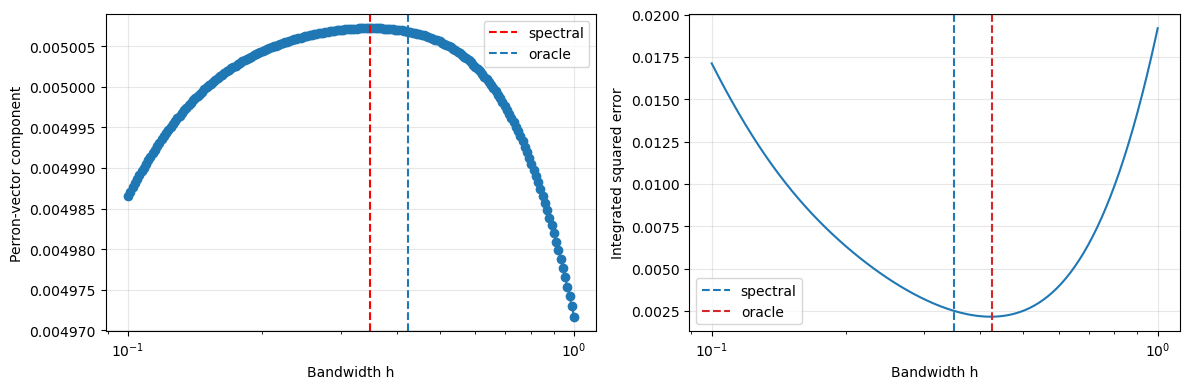

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

plot_perron_vector(
    h_grid=h_grid,
    vector=choice["perron_vector"],
    ax=axes[0],
    maximum_label="spectral",
)
axes[0].axvline(
    oracle_h,
    color="tab:blue",
    linestyle="--",
    label="oracle",
)
axes[0].legend()

axes[1].plot(h_grid, ise_values)
axes[1].axvline(
    spectral_h,
    color="tab:blue",
    linestyle="--",
    label="spectral",
)
axes[1].axvline(
    oracle_h,
    color="tab:red",
    linestyle="--",
    label="oracle",
)
axes[1].set_xscale("log")
axes[1].set_xlabel("Bandwidth h")
axes[1].set_ylabel("Integrated squared error")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [11]:
ise_values = exact_oracle_ise_values(
    samples=samples,
    h_grid=h_grid,
    sigma2=1.0,
)

mise_values = exact_mixture_mise_values(
    n=len(samples),
    h_grid=h_grid,
    weights=np.array([1.0]),
    means=np.array([0.0]),
    sigmas=np.array([1.0]),
)

ise_index = int(np.argmin(ise_values))
mise_index = int(np.argmin(mise_values))

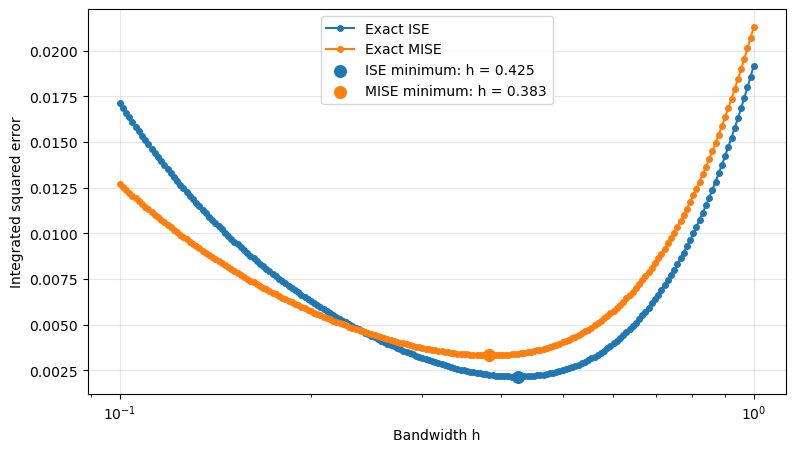

In [12]:
plt.figure(figsize=(9, 5))

plt.plot(
    h_grid,
    ise_values,
    marker="o",
    markersize=4,
    label="Exact ISE",
)

plt.plot(
    h_grid,
    mise_values,
    marker="o",
    markersize=4,
    label="Exact MISE",
)

plt.scatter(
    h_grid[ise_index],
    ise_values[ise_index],
    color="tab:blue",
    s=70,
    zorder=3,
    label=f"ISE minimum: h = {h_grid[ise_index]:.3f}",
)

plt.scatter(
    h_grid[mise_index],
    mise_values[mise_index],
    color="tab:orange",
    s=70,
    zorder=3,
    label=f"MISE minimum: h = {h_grid[mise_index]:.3f}",
)

plt.xscale("log")
plt.xlabel("Bandwidth h")
plt.ylabel("Integrated squared error")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## Distribution of Fourier-selected bandwidths

In [13]:
# Figure 3.4 uses a geometric grid from 0.01 to 2.0 with 201 candidates.
selection_h_grid = bandwidth_grid_linear_in_psi_beta()
selection_n_values = np.arange(100, 1001, 100)
selection_M = 200  # Increase to 1_000 for the thesis-sized experiment.
selection_sigma2 = 1.0
selection_tau = 1.0
selection_half_width = 12.0
selection_spatial_points = 2_048
selection_base_seed = 50_000

counts_by_n = {}

for position, n_value in enumerate(selection_n_values):
    print(f"Running n = {n_value}")
    counts_by_n[int(n_value)] = beta2_bandwidth_selection_counts(
        n=int(n_value),
        h_grid=selection_h_grid,
        M=selection_M,
        method="fourier",
        sigma2=selection_sigma2,
        tau=selection_tau,
        half_width=selection_half_width,
        spatial_points=selection_spatial_points,
        seed=selection_base_seed + position,
    )

maximum_relative_frequency = max(
    counts.max() / counts.sum()
    for counts in counts_by_n.values()
)
selection_distribution_figures = {}

for n_value in selection_n_values:
    n_value = int(n_value)
    figure = plot_bandwidth_distributions(
        h_grid=selection_h_grid,
        distributions={
            f"n={n_value}": counts_by_n[n_value]
        },
        y_max=1.05 * maximum_relative_frequency,
    )
    selection_distribution_figures[n_value] = figure
    figure.show()

Running n = 100
Running n = 200
Running n = 300
Running n = 400
Running n = 500
Running n = 600
Running n = 700
Running n = 800
Running n = 900
Running n = 1000


In [47]:
gaussian_mise_oracle_bandwidth(sample_size=len(samples))

0.383039453289006

In [48]:
h_grid = bandwidth_grid_linear_in_psi_beta(h_min=0.01, h_max=2.0, beta=2, grid_size=201)

In [49]:
counts = beta2_bandwidth_selection_counts(n=200, h_grid=h_grid, method="fourier", M=100)

In [50]:
counts

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 0, 3, 2, 5, 3, 3, 4, 4, 3, 4, 5, 5, 6, 5, 2, 2, 5,
       5, 4, 4, 3, 3, 3, 1, 0, 2, 2, 1, 1, 2, 1, 0, 1, 1, 1, 0, 0, 2, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0])

## AMISE-optimal bandwidth versus sample size

For a standard normal target density and a Gaussian kernel,

$$
h_{\mathrm{AMISE}}(n)=\left(\frac{4}{3n}\right)^{1/5},
$$

while the theoretical speed bandwidth is

$$
h_{\mathrm{speed}}(n)=\left(\frac{1}{4n}\right)^{1/5}
=\left(\frac{3}{16}\right)^{1/5}h_{\mathrm{AMISE}}(n).
$$

Both curves therefore have the same $n^{-1/5}$ decay but differ by a constant factor. The plot also includes the exact Gaussian MISE oracle $h_{\mathrm{oracle}}(n)$, obtained by numerically minimizing the finite-sample MISE rather than its asymptotic approximation.

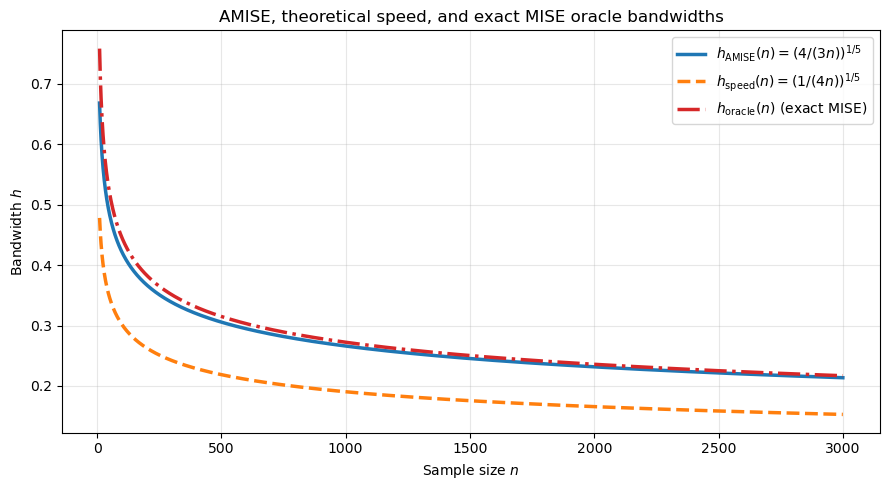

In [41]:
amise_n_values = np.arange(10, 3001)
amise_bandwidths = (4.0 / (3.0 * amise_n_values)) ** (1.0 / 5.0)
speed_bandwidths = (1.0 / (4.0 * amise_n_values)) ** (1.0 / 5.0)
oracle_bandwidths = np.array([
    gaussian_mise_oracle_bandwidth(sample_size=int(n_value))
    for n_value in amise_n_values
])

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(
    amise_n_values,
    amise_bandwidths,
    color="tab:blue",
    linewidth=2.5,
    label=r"$h_{\mathrm{AMISE}}(n)=(4/(3n))^{1/5}$",
)
ax.plot(
    amise_n_values,
    speed_bandwidths,
    color="tab:orange",
    linewidth=2.5,
    linestyle="--",
    label=r"$h_{\mathrm{speed}}(n)=(1/(4n))^{1/5}$",
)
ax.plot(
    amise_n_values,
    oracle_bandwidths,
    color="tab:red",
    linewidth=2.5,
    linestyle="-.",
    label=r"$h_{\mathrm{oracle}}(n)$ (exact MISE)",
)
ax.set_xlabel(r"Sample size $n$")
ax.set_ylabel(r"Bandwidth $h$")
ax.set_title(r"AMISE, theoretical speed, and exact MISE oracle bandwidths")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## Spectrally selected bandwidth versus sample size

For fixed $\lambda$ and a fixed bandwidth-grid size $N$, define

$$
\widehat h_{\lambda,N}(n)=h_{\operatorname*{arg\,max}_i v_i},
\qquad S_{\lambda}=\exp(-\lambda D_2),
$$

where $v$ is the Perron vector of $S_{\lambda}$. The parameters $\lambda$, $N$, the number of repetitions $M$, the bandwidth interval, the sample-size values, and the random seed can be changed below. For each of the $M$ independent standard-normal samples, prefixes are reused across $n$. The plot reports the median selected bandwidth and its interquartile range.

completed repetition 1/1


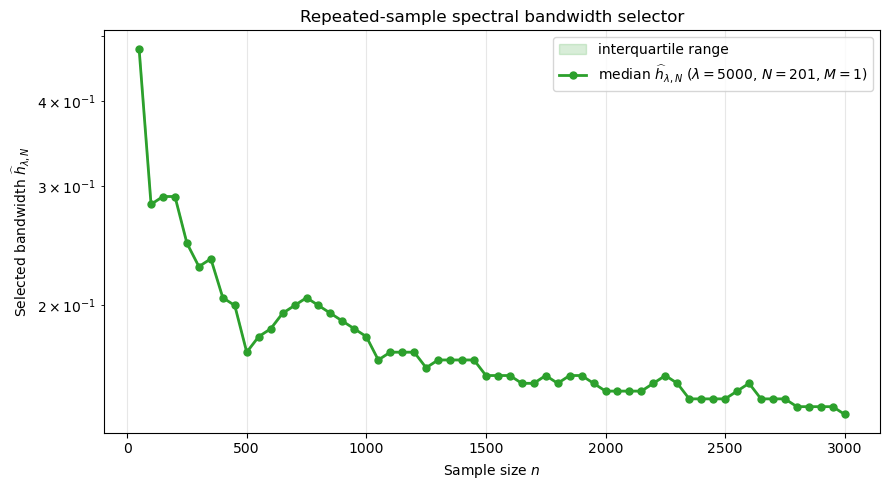

In [45]:
# Main parameters: choose lambda, N, and M here.
spectral_path_lambda = 5000.0
spectral_path_N = 201
spectral_path_M = 1

# Additional experiment settings.
spectral_path_n_values = np.arange(50, 3001, 50)
spectral_path_h_min = 0.01
spectral_path_h_max = 2.0
spectral_path_beta = 2.0
spectral_path_seed = 12345
spectral_path_half_width = 12.0
spectral_path_spatial_points = 2_048

spectral_path_n_values = np.asarray(spectral_path_n_values, dtype=int)
if spectral_path_n_values.ndim != 1 or len(spectral_path_n_values) == 0:
    raise ValueError("spectral_path_n_values must be a nonempty one-dimensional array.")
if np.any(spectral_path_n_values < 1):
    raise ValueError("All sample sizes must be positive.")
if spectral_path_lambda <= 0.0:
    raise ValueError("spectral_path_lambda must be positive.")
if spectral_path_N < 2:
    raise ValueError("spectral_path_N must be at least two.")
if spectral_path_M < 1:
    raise ValueError("spectral_path_M must be positive.")

spectral_path_h_grid = bandwidth_grid_linear_in_psi_beta(
    h_min=spectral_path_h_min,
    h_max=spectral_path_h_max,
    beta=spectral_path_beta,
    grid_size=spectral_path_N,
)
spectral_path_rng = np.random.default_rng(spectral_path_seed)
spectral_path_full_samples = spectral_path_rng.normal(
    size=(spectral_path_M, int(np.max(spectral_path_n_values)))
)
spectral_path_selected_indices = np.empty(
    (spectral_path_M, len(spectral_path_n_values)), dtype=int
)

for repetition in range(spectral_path_M):
    for position, n_value in enumerate(spectral_path_n_values):
        current_similarity = beta2_similarity_matrix_fft(
            samples=spectral_path_full_samples[repetition, :n_value],
            h_grid=spectral_path_h_grid,
            tau=spectral_path_lambda,
            half_width=spectral_path_half_width,
            spatial_points=spectral_path_spatial_points,
        )
        current_choice = spectral_choice_from_similarity(current_similarity)
        spectral_path_selected_indices[repetition, position] = int(
            current_choice["selected_index"]
        )
    print(f"completed repetition {repetition + 1}/{spectral_path_M}")

spectral_path_selected_bandwidth_samples = spectral_path_h_grid[
    spectral_path_selected_indices
]
(
    spectral_path_q25_bandwidths,
    spectral_path_selected_bandwidths,
    spectral_path_q75_bandwidths,
) = np.quantile(
    spectral_path_selected_bandwidth_samples,
    [0.25, 0.50, 0.75],
    axis=0,
)

fig, ax = plt.subplots(figsize=(9, 5))
ax.fill_between(
    spectral_path_n_values,
    spectral_path_q25_bandwidths,
    spectral_path_q75_bandwidths,
    color="tab:green",
    alpha=0.18,
    label="interquartile range",
)
ax.plot(
    spectral_path_n_values,
    spectral_path_selected_bandwidths,
    color="tab:green",
    linewidth=2.0,
    marker="o",
    markersize=5,
    label=rf"median $\widehat{{h}}_{{\lambda,N}}$ ($\lambda={spectral_path_lambda:g}$, $N={spectral_path_N}$, $M={spectral_path_M}$)",
)
ax.set_xlabel(r"Sample size $n$")
ax.set_ylabel(r"Selected bandwidth $\widehat{h}_{\lambda,N}$")
ax.set_title(r"Repeated-sample spectral bandwidth selector")
ax.set_yscale("log")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## Comparison of all three bandwidth curves

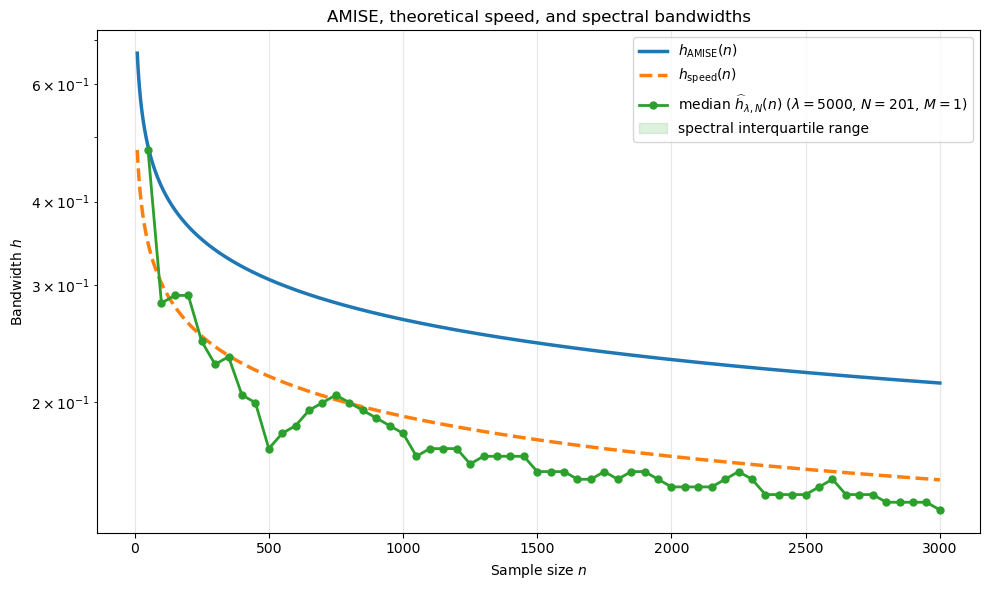

In [46]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(
    amise_n_values,
    amise_bandwidths,
    color="tab:blue",
    linewidth=2.5,
    label=r"$h_{\mathrm{AMISE}}(n)$",
)
ax.plot(
    amise_n_values,
    speed_bandwidths,
    color="tab:orange",
    linewidth=2.5,
    linestyle="--",
    label=r"$h_{\mathrm{speed}}(n)$",
)
ax.plot(
    spectral_path_n_values,
    spectral_path_selected_bandwidths,
    color="tab:green",
    linewidth=2.0,
    marker="o",
    markersize=5,
    label=rf"median $\widehat{{h}}_{{\lambda,N}}(n)$ ($\lambda={spectral_path_lambda:g}$, $N={spectral_path_N}$, $M={spectral_path_M}$)",
)
ax.fill_between(
    spectral_path_n_values,
    spectral_path_q25_bandwidths,
    spectral_path_q75_bandwidths,
    color="tab:green",
    alpha=0.15,
    label="spectral interquartile range",
)
ax.set_xlabel(r"Sample size $n$")
ax.set_ylabel(r"Bandwidth $h$")
ax.set_title(r"AMISE, theoretical speed, and spectral bandwidths")
ax.set_yscale("log")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## Spectral bandwidth relative to the theoretical speed bandwidth

For the standard normal target,

$$
h_{\mathrm{speed}}(n)=\left(\frac{1}{4n}\right)^{1/5}.
$$

The following plot tests whether the median of $\widehat h_{\lambda,N}(n)/h_{\mathrm{speed}}(n)$ approaches one for fixed $\lambda$ and fixed $N$. The shaded band is the interquartile range across the $M$ repeated samples selected above.

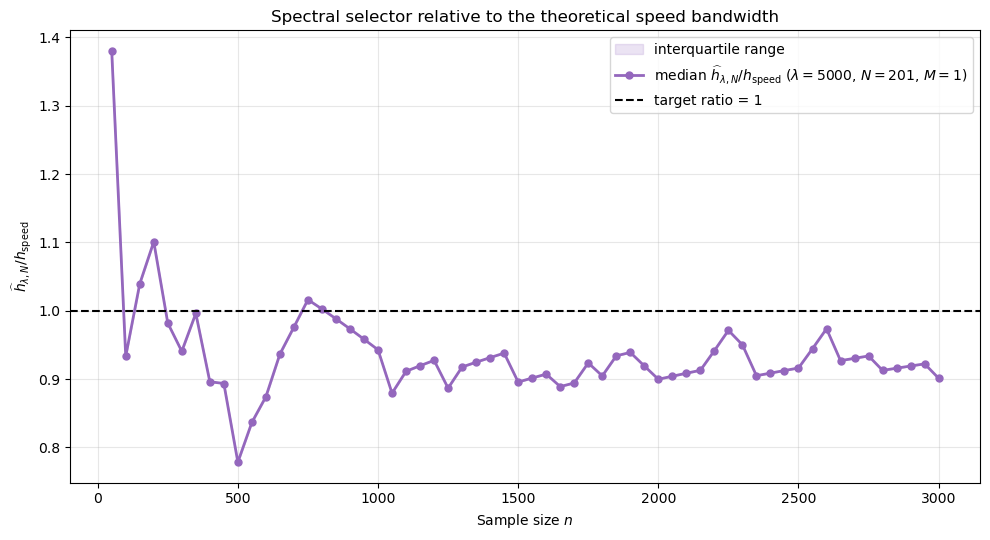

In [47]:
spectral_path_speed_bandwidths = (
    1.0 / (4.0 * spectral_path_n_values)
) ** (1.0 / 5.0)
spectral_path_speed_ratio_samples = (
    spectral_path_selected_bandwidth_samples
    / spectral_path_speed_bandwidths[None, :]
)
(
    spectral_path_q25_speed_ratios,
    spectral_path_speed_ratios,
    spectral_path_q75_speed_ratios,
) = np.quantile(
    spectral_path_speed_ratio_samples,
    [0.25, 0.50, 0.75],
    axis=0,
)

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.fill_between(
    spectral_path_n_values,
    spectral_path_q25_speed_ratios,
    spectral_path_q75_speed_ratios,
    color="tab:purple",
    alpha=0.18,
    label="interquartile range",
)
ax.plot(
    spectral_path_n_values,
    spectral_path_speed_ratios,
    color="tab:purple",
    linewidth=2.0,
    marker="o",
    markersize=5,
    label=rf"median $\widehat{{h}}_{{\lambda,N}}/h_{{\mathrm{{speed}}}}$ ($\lambda={spectral_path_lambda:g}$, $N={spectral_path_N}$, $M={spectral_path_M}$)",
)
ax.axhline(
    1.0,
    color="black",
    linewidth=1.5,
    linestyle="--",
    label="target ratio = 1",
)
ax.set_xlabel(r"Sample size $n$")
ax.set_ylabel(r"$\widehat{h}_{\lambda,N}/h_{\mathrm{speed}}$")
ax.set_title(r"Spectral selector relative to the theoretical speed bandwidth")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()